## **Learning objectives**

By the end of this notebook, you should be able to:
* Load and prepare a dataset.
* Train and evaluate linear, non-linear, and ensemble regression models

## 1. __Introduction__

We wish to examine and understand how socio-economic and environmental factors contribute to the rate of deforestation. We have been given a dataset that captures this information. Our goal is to model this relationship through regression analysis.

In the sections that follow, we explore the process of training and evaluating various regression models on a similar dataset. Through the model experimentation process, we are able to compare the performance of various models, guiding the selection of the best model for predicting our target variable.

## 2. __Dataset and libraries__

We begin by setting up our working environment by importing the necessary `Python` libraries that we will use throughout the notebook.

Then we load and inspect the dataset to get familiar with its structure and contents.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import StackingRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
df = pd.read_csv("../data/enviro_indicators.csv")
display(df.head())

,forest_coverage,biodiversity_index,protected_areas,deforestation_rate,carbon_sequestration,soil_erosion,land_degradation,rural_population,population_density
0,36.217808,6.505159,14.832708,36.583106,53.128459,7.987880,55.020903,35.912142,468.715839
1,76.550001,94.888554,23.994363,123.384939,279.836286,13.013811,41.655073,34.639379,351.054600
2,61.239576,96.563203,9.932348,115.743745,237.834951,13.037065,26.951490,78.380633,289.329973
3,51.906094,80.839735,33.076894,111.752369,149.948515,11.179719,27.460479,43.585863,57.616482
4,20.921305,30.461377,7.609273,46.450326,103.939415,2.715506,46.297784,73.522793,311.353541


In [5]:
for col in df.columns:
    print(f"{col:<20}: {df[col].dtype}")

forest_coverage     : float64
biodiversity_index  : float64
protected_areas     : float64
deforestation_rate  : float64
carbon_sequestration: float64
soil_erosion        : float64
land_degradation    : float64
rural_population    : float64
population_density  : float64


In [6]:
# Check the shape of the dataset
print(f"Dataset shape: {df.shape}")

Dataset shape: (32, 9)


In [8]:
# view the correlation matrix
corr_matrix = df.corr()
display(corr_matrix)

,forest_coverage,biodiversity_index,protected_areas,deforestation_rate,carbon_sequestration,soil_erosion,land_degradation,rural_population,population_density
forest_coverage,1.000000,0.274022,0.108666,0.556136,0.053950,-0.109275,0.154287,0.022843,0.027884
biodiversity_index,0.274022,1.000000,-0.067212,0.922463,0.009418,-0.062205,-0.136184,0.042478,-0.135042
protected_areas,0.108666,-0.067212,1.000000,0.120202,0.146215,0.321587,-0.113558,0.172193,-0.001360
deforestation_rate,0.556136,0.922463,0.120202,1.000000,0.063443,-0.082024,-0.092885,0.105760,-0.126157
carbon_sequestration,0.053950,0.009418,0.146215,0.063443,1.000000,0.237919,0.268428,-0.017830,-0.344947
soil_erosion,-0.109275,-0.062205,0.321587,-0.082024,0.237919,1.000000,-0.110673,0.146636,0.046528
land_degradation,0.154287,-0.136184,-0.113558,-0.092885,0.268428,-0.110673,1.000000,-0.085273,-0.137509
rural_population,0.022843,0.042478,0.172193,0.105760,-0.017830,0.146636,-0.085273,1.000000,0.226600
population_density,0.027884,-0.135042,-0.001360,-0.126157,-0.344947,0.046528,-0.137509,0.226600,1.000000


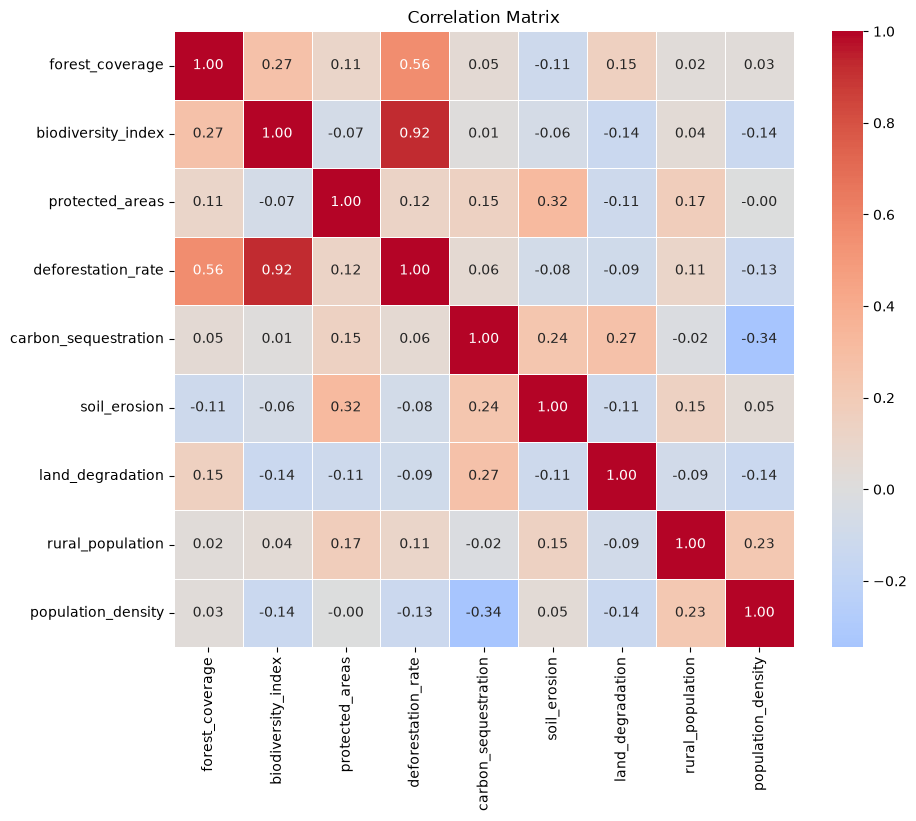

In [10]:
# plot the correlation matrix as a heatmap

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    cmap="coolwarm", 
    center=0,
    linewidths=0.5,
    fmt=".2f"

)
plt.title("Correlation Matrix")
plt.show()

### **Correlation matrix observations**

- **Biodiversity index and deforestation rate** have a very strong positive correlation (**0.92**), making biodiversity index the strongest linear predictor.
- **Forest coverage and deforestation rate** show a moderate positive correlation (**0.56**).
- Other variables have weak correlations with deforestation rate, generally between **-0.13 and 0.12**.
- **Biodiversity index and deforestation rate may introduce multicollinearity** if both are used as predictors, so this should be checked during modelling.

### __Data Preprocessing__

In [11]:
# Separate the feature and target variables
X = df.drop(['deforestation_rate'], axis=1)
y = df['deforestation_rate']

# Split the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and apply MinMaxScaler for scaling
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### __Model Training and Evaluation__



In [14]:
# Preparing data for simple linear regression

X_train_lr = pd.DataFrame(X_train_scaled, columns=X.columns)[['biodiversity_index']]
X_test_lr = pd.DataFrame(X_test_scaled, columns=X.columns)[['biodiversity_index']]

# Training the model
lr = LinearRegression()
lr.fit(X_train_lr, y_train)

# Making predictions on the test data
y_pred = lr.predict(X_test_lr)

# Evaluating the model
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")
print(f"MSE: {mean_squared_error(y_test, y_pred):.2f}")

R² Score: 0.7797
MSE: 108.58


Create a generic function for model training and evaluation

In [15]:
def train_and_evaluate_model(model):

    # Train the model on the scaled training data
    model.fit(X_train_scaled, y_train)

    # Make predictions on the scaled test set
    y_pred = model.predict(X_test_scaled)

    # Evaluate the model
    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)

    return model, r2, mse

In [16]:
# Training and evaluating the multiple linear regression model
linear_model, linear_r2, linear_mse = train_and_evaluate_model(LinearRegression())
print(f"Linear regression - R²: {linear_r2:.4f}, MSE: {linear_mse:.2f}")

Linear regression - R²: 0.9641, MSE: 17.70


### **Decision Tree**

In [32]:
# Training and evaluating the decision tree regression model
tree_model, tree_r2, tree_mse = train_and_evaluate_model(
    DecisionTreeRegressor(
        random_state=42, 
        max_depth=6)
)
print(f"Decision tree regression - R²: {tree_r2:.4f}, MSE: {tree_mse:.2f}")

Decision tree regression - R²: 0.8269, MSE: 85.32


### **Random Forest**

In [26]:
# Training and evaluating the random forest regression model
forest_model, forest_r2, forest_mse = train_and_evaluate_model(
    RandomForestRegressor(
        random_state=42, 
        max_depth=5)
)
print(f"Random Forest Regression - R²: {forest_r2:.4f}, MSE: {forest_mse:.2f}")

Random Forest Regression - R²: 0.8804, MSE: 58.97


### __Stacking__

In [33]:
# Define the base models: these are models that have already been trained
base_models = [
    ('linear_regression', linear_model),
    ('random_forest', forest_model)
]

# Define the meta-learner
final_estimator = LinearRegression()

In [34]:
# Training and evaluating the stacking regression model
stacking_model, stacking_r2, stacking_mse = train_and_evaluate_model(
    StackingRegressor(
        estimators=base_models, 
        final_estimator=final_estimator, 
        cv=5)
)
print(f"Stacking Regression - R²: {stacking_r2:.4f}, MSE: {stacking_mse:.2f}")

Stacking Regression - R²: 0.9632, MSE: 18.14


### **Business Insights Summary**

- **Biodiversity index is the strongest predictor** of deforestation rate, with a correlation of **0.92**. Biodiversity protection should therefore be a central focus of deforestation-reduction strategies.
- **Forest coverage is also relevant**, showing a moderate positive relationship (**0.56**) with deforestation rate. Areas with higher forest coverage may require stronger monitoring because they have more forest resources at risk.
- Other indicators show weak linear relationships with deforestation rate, so they should not be used in isolation for decision-making.
- The **multiple linear regression model performed best** on the test set (**$R^2$ = 0.964, MSE = 17.70**). The stacking model produced a similar but slightly weaker result, while tree-based models performed less effectively.
- The results can support **risk prioritisation, conservation planning, and targeted monitoring** of regions with high biodiversity and forest coverage.

These findings indicate association rather than causation. Since the dataset contains only 32 observations and seven test cases, the results should be validated using a larger and more representative dataset before operational deployment